In [ ]:
import pandas as pd
import numpy as np
import io

from google.colab import files
uploaded = files.upload()

# Get the first uploaded filename and read its bytes
file_name = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print(df.head())

Saving dataset.csv to dataset (2).csv
  GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
0      M   65        1               1        1              2   
1      F   55        1               2        2              1   
2      F   78        2               2        1              1   
3      M   60        2               1        1              1   
4      F   80        1               1        2              1   

   CHRONIC_DISEASE  FATIGUE  ALLERGY  WHEEZING  ALCOHOL_CONSUMING  COUGHING  \
0                2        1        2         2                  2         2   
1                1        2        2         2                  1         1   
2                1        2        1         2                  1         1   
3                2        1        2         1                  1         2   
4                1        2        1         2                  1         1   

   SHORTNESS_OF_BREATH  SWALLOWING_DIFFICULTY  CHEST_PAIN LUNG_CANCER  
0                 

Data preprocessing completed
Training and testing data created
AdaBoost Classification model trained successfully
AdaBoost Classification Results
Accuracy Score: 0.5266666666666666

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.50      0.52       302
           1       0.52      0.55      0.54       298

    accuracy                           0.53       600
   macro avg       0.53      0.53      0.53       600
weighted avg       0.53      0.53      0.53       600



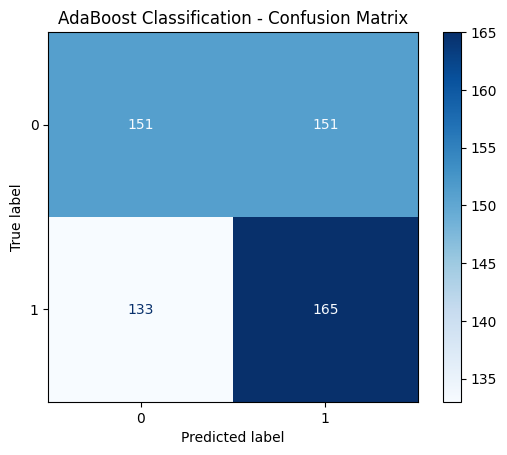

In [ ]:
from sklearn.preprocessing import LabelEncoder

df = df.copy()

# Remove unnecessary columns if present
df.drop(
    columns=["Patient_ID", "Diagnosis_Date"],
    errors="ignore",
    inplace=True
)

# Convert categorical feature columns into numbers
feature_le = LabelEncoder()
for col in df.select_dtypes(include="object").columns:
    if col != "LUNG_CANCER":
        df[col] = feature_le.fit_transform(df[col].astype(str))

# Use a dedicated LabelEncoder for the target column
target_le = LabelEncoder()
df["LUNG_CANCER"] = target_le.fit_transform(df["LUNG_CANCER"].astype(str))

# Separate input and target
X = df.drop("LUNG_CANCER", axis=1)
y = df["LUNG_CANCER"]

print("Data preprocessing completed")
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training and testing data created")
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Create the AdaBoost Classifier model
model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3),
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predict the output
y_pred = model.predict(X_test)

print("AdaBoost Classification model trained successfully")
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

accuracy = accuracy_score(y_test, y_pred)
print("AdaBoost Classification Results")
print("Accuracy Score:", accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=target_le.classes_))

# Plot Confusion Matrix using target_le.classes_
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_le.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("AdaBoost Classification - Confusion Matrix")
plt.show()